In [130]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [131]:
c1 = 1
c2 = 7
c3 = 8
A = (c1 % 3) + 1
B = (c2 % 4) + 1
C = (c3 % 5) + 1

# D1

## 1

In [132]:
def euler_step(fun, t0, x0, h):
    """
    Pojedynczy krok w metodzie Eulera.

    Parametry
    ----------
    fun : obiekt wywoływalny (callable)
        Prawa strona układu równań.
    t0 : float
        Krok czasowy t_n.
    x0 : ndarray, wymiaru (d,)
        Wartość przybliżenia x_n.
    h : float
        Krok czasowy.

    Zwraca
    -------
    x_new : ndarray, wymiaru (d,)
        Rozwiązanie przybliżone w punkcie t_(n+1).
    """
    x_new = x0 + h * fun(t0, x0)
    return x_new

In [133]:
def ab3_step(fun, t0, t1, t2, x0, x1, x2, h):
    """
    Pojedynczy krok w 3-krokowej metodzie Adamsa-Bashfortha.

    Parametry
    ----------
    fun : obiekt wywoływalny (callable)
        Prawa strona układu równań.
    t0 : float
        Krok czasowy t_n.
    t1 : float
        Krok czasowy t_(n+1)
    t2 : float
        Krok czasowy t_(n+2)
    x0 : ndarray, wymiaru (d,)
        Wartość przybliżenia x_n.
    x1 : ndarray, wymiaru (d,)
        Wartość przybliżenia x_(n+1)
    x2 : ndarray, wymiaru (d,)
        Waartość przybliżenia x_(n+2)
    h : float
        Krok czasowy.

    Zwraca
    -------
    x_new : ndarray, wymiaru (d,)
        Rozwiązanie przybliżone w punkcie t_(n+3).
    """
    x_new = x2 + (h / 12.0) * (23 * fun(t2, x2) - 16 * fun(t1, x1) + 5 * fun(t0, x0))
    return x_new

In [134]:
class AB3(integrate.OdeSolver):
    """
    Stałokrokowa 3-krokowa metoda Adamsa-Bashfortha (rzędu 3).

    (parametry i atrybuty jak w metodach zaimplementowanych w pakiecie `SciPy`.)
    """
    def __init__(self, fun, t0, y0, t_bound, max_step=np.inf,
                 rtol=1e-3, atol=1e-6, vectorized=False,
                 first_step=None, **extraneous):
        integrate._ivp.common.warn_extraneous(extraneous)
        super(AB3, self).__init__(fun, t0, y0, t_bound, vectorized,
                                    support_complex=True)
        self.y_old0 = None
        self.y_old1 = None
        self.y_old2 = None
        self.t_old0 = None
        self.t_old1 = None
        self.t_old2 = None
        self.t0 = t0
        self.max_step = integrate._ivp.common.validate_max_step(max_step)
        self.error_estimator_order = 3 #metoda rzędu 3
        self.rtol, self.atol = integrate._ivp.common.validate_tol(rtol, atol, self.n)
        self.f = self.fun(self.t, self.y)
        if first_step is None:
            self.h_abs = integrate._ivp.common.select_initial_step(
                self.fun, self.t, self.y, self.f, self.direction,
                self.error_estimator_order, self.rtol, self.atol)
        else:
            self.h_abs = integrate._ivp.common.validate_first_step(first_step, t0, t_bound)

    def _step_impl(self):
        t = self.t
        y = self.y
        h = self.h_abs * self.direction
        t_new = t + h

        if self.t_old0 is None:
            y_new = euler_step(self.fun, t, y, h)
            self.t_old0 = t
            self.y_old0 = y

        elif self.t_old1 is None:
            y_new = euler_step(self.fun, t, y, h)
            self.t_old1 = t
            self.y_old1 = y

        else:
            self.t_old2 = t
            self.y_old2 = y

            y_new = ab3_step(
                self.fun,
                self.t_old0, self.t_old1, self.t_old2,
                self.y_old0, self.y_old1, self.y_old2,
                h
            )

            self.t_old0 = self.t_old1
            self.y_old0 = self.y_old1
            self.t_old1 = self.t_old2
            self.y_old1 = self.y_old2

        self.t, self.y = t_new, y_new

        return True, None

    def _dense_output_impl(self):
        return None


### 2

In [135]:
def fun_hw(t, x):
    return -A * x + B * np.sin(t)

In [136]:
sol_true = lambda t: ((C * (3 + A ** 2)) / (2 * (1 + A ** 2))) * np.exp(-A*t) + (C/(1+A**2)) * (A*np.sin(t) - np.cos(t))

In [137]:
tspan = [0, 3]
h = 0.1
x0 = C / 2.0

sol_ab3 = integrate.solve_ivp(fun_hw, tspan, [x0], method=AB3, first_step=h)

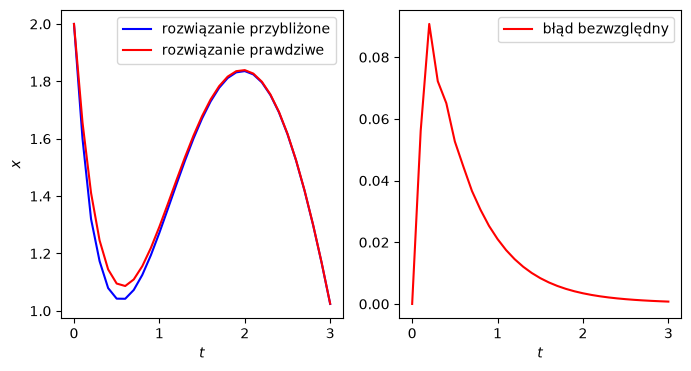

In [138]:
_, axes = plt.subplots(1, 2, figsize=(8,4))
axes[0].plot(sol_ab3.t, sol_ab3.y[0], 'b', label="rozwiązanie przybliżone")
axes[0].plot(sol_ab3.t, sol_true(sol_ab3.t), 'r', label="rozwiązanie prawdziwe")
axes[0].set_xlabel("$t$")
axes[0].set_ylabel("$x$")
axes[0].legend()

axes[1].plot(sol_ab3.t, np.abs(sol_ab3.y[0]-sol_true(sol_ab3.t)), 'r', label="błąd bezwzględny")
axes[1].set_xlabel("$t$")
axes[1].legend()

plt.show()

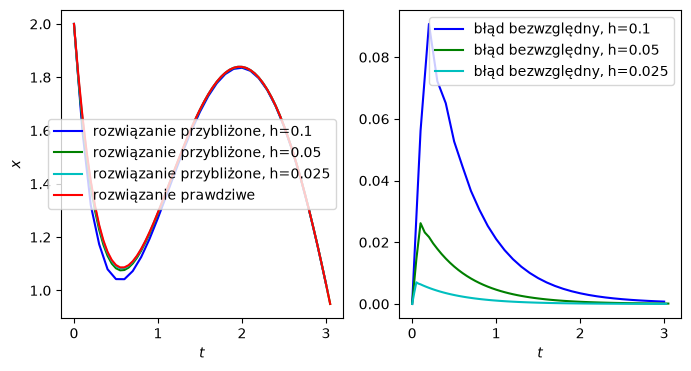

In [139]:
hs = [0.1, 0.05, 0.025]
sol_ab3s = [integrate.solve_ivp(fun_hw, tspan, [x0], method=AB3, first_step=h_step) for h_step in hs]

_, axes = plt.subplots(1, 2, figsize=(8,4))
axes[0].plot(sol_ab3s[0].t, sol_ab3s[0].y[0], 'b', label="rozwiązanie przybliżone, h=0.1")
axes[0].plot(sol_ab3s[1].t, sol_ab3s[1].y[0], 'g', label="rozwiązanie przybliżone, h=0.05")
axes[0].plot(sol_ab3s[2].t, sol_ab3s[2].y[0], 'c', label="rozwiązanie przybliżone, h=0.025")
axes[0].plot(sol_ab3s[1].t, sol_true(sol_ab3s[1].t), 'r', label="rozwiązanie prawdziwe")
axes[0].set_xlabel("$t$")
axes[0].set_ylabel("$x$")
axes[0].legend()

axes[1].plot(sol_ab3s[0].t, np.abs(sol_ab3s[0].y[0]-sol_true(sol_ab3s[0].t)), 'b', label="błąd bezwzględny, h=0.1")
axes[1].plot(sol_ab3s[1].t, np.abs(sol_ab3s[1].y[0]-sol_true(sol_ab3s[1].t)), 'g', label="błąd bezwzględny, h=0.05")
axes[1].plot(sol_ab3s[2].t, np.abs(sol_ab3s[2].y[0]-sol_true(sol_ab3s[2].t)), 'c', label="błąd bezwzględny, h=0.025")
axes[1].set_xlabel("$t$")
axes[1].legend()

plt.show()

In [ ]:
errors = []

for h, sol in zip(hs, sol_ab3s):
    # if not sol.success:
    #     raise RuntimeError(sol.message)

    # i = np.argmin(np.abs(sol.t - 3.0))
    # if not np.isclose(sol.t[i], 3.0, rtol=0, atol=1e-10):
    #     raise ValueError(f"Brak punktu t=3 dla h={h}")

    error = abs(sol.y[0, i] - sol_true(3.0))
    errors.append(error)
    print(f"h={h}: błąd = {error:.8e}")

for i in range(len(hs) - 1):
    if errors[i] > 0 and errors[i + 1] > 0:
        p = np.log(errors[i] / errors[i + 1]) / np.log(hs[i] / hs[i + 1])
        print(f"Rząd dla h={hs[i]} i h={hs[i + 1]}: {p:.4f}")
    else:
        print("Nie można wyznaczyć rzędu dla zerowego błędu.")

h=0.1: błąd = 5.75273484e-01
h=0.05: błąd = 7.75273484e-01
h=0.025: błąd = 8.75273484e-01
Rząd dla h=0.1 i h=0.05: -0.4305
Rząd dla h=0.05 i h=0.025: -0.1750


# D2

<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_22989/2158687739.py:17: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(h_test.real, h_test.imag, 'r*', markersize=12, label=f'Punkt testowy $\hat{{h}}_{{test}} = {-A} - {B}i$')
/tmp/ipykernel_22989/2158687739.py:20: SyntaxWarning: invalid escape sequence '\h'
  plt.xlabel('Re($\hat{h}$)')
/tmp/ipykernel_22989/2158687739.py:21: SyntaxWarning: invalid escape sequence '\h'
  plt.ylabel('Im($\hat{h}$)')


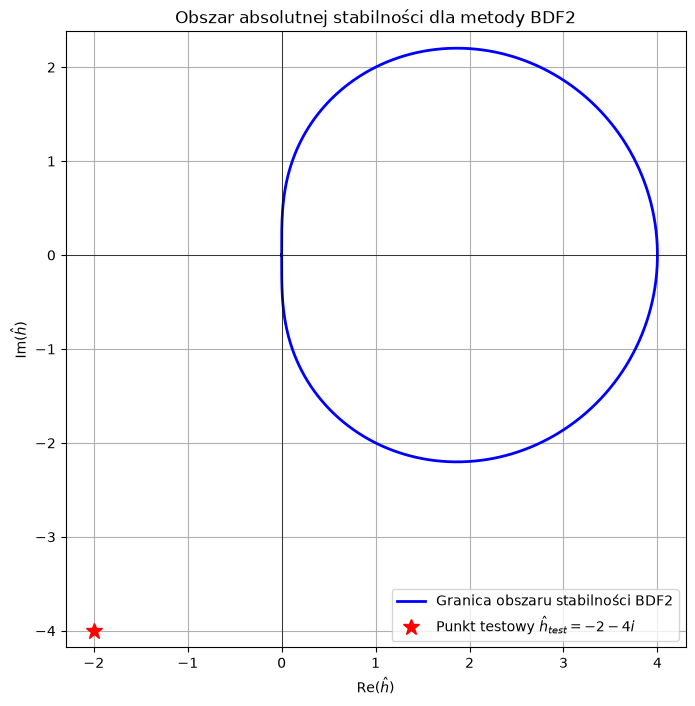

Analiza dla punktu testowego h_test = (-2-4j):
Moduły pierwiastków wielomianu stabilności:
  |r_1| = 0.4122
  |r_2| = 0.2282

Odp: Punkt h_test leży wewnątrz obszaru absolutnej stabilności metody BDF2.


In [141]:
# --- 2. Wykres granicy absolutnej stabilności ---

# Parametryzacja r = exp(i*theta) dla theta w przedziale [0, 2pi]
theta = np.linspace(0, 2*np.pi, 2000)
r_param = np.exp(1j * theta)

# Wyznaczanie h_hat(theta) przekształcając p(r)=0 do postaci h_hat = rho(r)/sigma(r)
h_hat = (3*r_param**2 - 4*r_param + 1) / (2*r_param**2)

# Punkt testowy wskazany w zadaniu
h_test = -A - B*1j

plt.figure(figsize=(8, 8))
plt.plot(h_hat.real, h_hat.imag, 'b-', label='Granica obszaru stabilności BDF2', linewidth=2)

# Nanoszenie wyróżnionego markera dla punktu testowego
plt.plot(h_test.real, h_test.imag, 'r*', markersize=12, label=f'Punkt testowy $\hat{{h}}_{{test}} = {-A} - {B}i$')

plt.title('Obszar absolutnej stabilności dla metody BDF2')
plt.xlabel('Re($\hat{h}$)')
plt.ylabel('Im($\hat{h}$)')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

# --- 3. Weryfikacja przynależności punktu do obszaru stabilności ---

# Zgodnie z teorią dla metod BDF obszar stabilności znajduje się na zewnątrz
# nakreślonej krzywej parametrycznej (obejmuje m.in całą lewą półpłaszczyznę).
# Możemy jednoznacznie ocenić punkt sprawdzając pierwiastki wielomianu stabilności p(r).

wspolczynniki = [3 - 2*h_test, -4, 1]
pierwiastki = np.roots(wspolczynniki)

print(f"Analiza dla punktu testowego h_test = {h_test}:")
print("Moduły pierwiastków wielomianu stabilności:")
for i, p in enumerate(pierwiastki):
    print(f"  |r_{i+1}| = {np.abs(p):.4f}")

# Jeśli oba pierwiastki leżą wewnątrz lub na brzegu koła jednostkowego (<=1), metoda jest absolutnie stabilna.
if all(np.abs(p) <= 1 for p in pierwiastki):
    print("\nOdp: Punkt h_test leży wewnątrz obszaru absolutnej stabilności metody BDF2.")
else:
    print("\nOdp: Punkt h_test leży POZA obszarem absolutnej stabilności metody BDF2.")